<a href="https://colab.research.google.com/github/ana-lan/invasive-plant-species-detection/blob/main/Invasive_Plant_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Setup

## Kaggle Config

In [ ]:
# Kaggle API
!pip install -q kaggle

In [ ]:
# upload Kapple API config file (kaggle.json)
from google.colab import files
files.upload()

In [ ]:
# kaggle config
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


## Directory Config

In [ ]:
# save progress on google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# set file paths
import os

drive_path = '/content/drive/MyDrive/invasive_species_data'
train_path = os.path.join(drive_path, 'train_images')
csv_path = os.path.join(drive_path, 'train_labels.csv')
image_path = os.path.join(train_path, 'train')

# archive files to be downloaded
train7z = os.path.join(drive_path, 'train.7z')
csv_zip = os.path.join(drive_path, 'train_labels.csv.zip')

# where to save the model
model_path = os.path.join(drive_path, 'model.pth')

## Download and Prepare Data

In [ ]:
# download dataset from Kaggle if files are missing
if not os.path.exists(train7z) or not os.path.exists(csv_zip):
    !kaggle competitions download -c invasive-species-monitoring -p "$drive_path"
else:
    print("Kaggle files already downloaded.")

Traceback (most recent call last):
  File "/usr/local/bin/kaggle", line 4, in <module>
    from kaggle.cli import main
  File "/usr/local/lib/python3.11/dist-packages/kaggle/__init__.py", line 6, in <module>
    api.authenticate()
  File "/usr/local/lib/python3.11/dist-packages/kaggle/api/kaggle_api_extended.py", line 433, in authenticate
    raise IOError('Could not find {}. Make sure it\'s located in'
OSError: Could not find kaggle.json. Make sure it's located in /root/.kaggle. Or use the environment method. See setup instructions at https://github.com/Kaggle/kaggle-api/


In [ ]:
# unzip the main zip file
# check if needs to be unzipped
kaggle_zip = os.path.join(drive_path, 'invasive-species-monitoring.zip')
expected_files = ["train.7z", "train_labels.csv.zip"]

# only unzip if any of the key files are missing
need_unzip = any(not os.path.exists(os.path.join(drive_path, f)) for f in expected_files)

if os.path.exists(kaggle_zip) and need_unzip:
    print("Unzipping Kaggle zip file...")
    !unzip -o "$kaggle_zip" -d "$drive_path"
else:
    print("Kaggle zip already unzipped or not found.")

Kaggle zip already unzipped or not found.


In [ ]:
# extract archives
if not os.path.exists(train_path):
    !7z x "$train7z" -o"$train_path"
else:
    print("Train images already extracted.")

if not os.path.exists(csv_path):
    !unzip "$csv_zip" -d "$drive_path"
else:
    print("CSV already extracted.")


7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,2 CPUs Intel(R) Xeon(R) CPU @ 2.00GHz (50653),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan /content/drive/MyDrive/invasive_species_data/                                                       
ERROR: No such file or directory
/content/drive/MyDrive/invasive_species_data/train.7z



System ERROR:
Unknown error -2147024894
unzip:  cannot find or open /content/drive/MyDrive/invasive_species_data/train_labels.csv.zip, /content/drive/MyDrive/invasive_species_data/train_labels.csv.zip.zip or /content/drive/MyDrive/invasive_species_data/train_labels.csv.zip.ZIP.


In [ ]:
import pandas as pd

labels_df = pd.read_csv(csv_path)
labels_df.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/invasive_species_data/train_labels.csv'

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

# show 5 random samples
sample = labels_df.sample(5)
for i, row in sample.iterrows():
    img_path = os.path.join(image_path, f"{row['name']}.jpg")
    print(f"Opening: {img_path}")
    img = Image.open(img_path)
    plt.imshow(img)
    plt.title(f"Invasive: {row['invasive']}")
    plt.axis("off")
    plt.show()

# Segmentation

In [ ]:
import cv2
import numpy as np

def texture_segmentation(img):
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # apply Sobel edge detection
    sobelx = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=5)
    sobely = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=5)
    sobel = np.hypot(sobelx, sobely)

    return sobel

In [ ]:
import matplotlib.pyplot as plt

def show_texture_segmentation(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)
    sobel = texture_segmentation(img)

    plt.figure(figsize=(10,5))
    plt.subplot(1,2,1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(sobel, cmap='gray')
    plt.title("Texture Segmentation")
    plt.axis("off")
    plt.show()

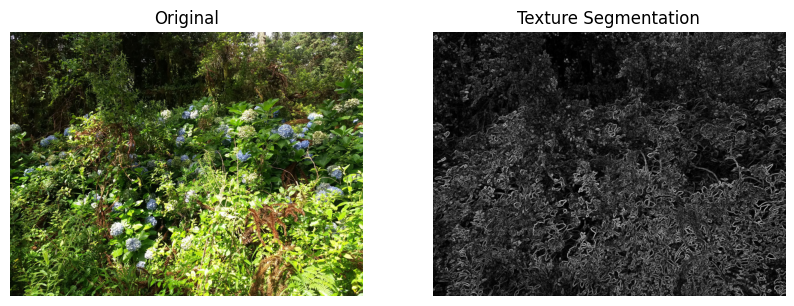

In [ ]:
# display one random image segmentation
sample_name = str(labels_df.sample(1)['name'].values[0])
sample_path = os.path.join(image_path, f"{sample_name}.jpg")
show_texture_segmentation(sample_path)

# Preprocessing

In [ ]:
from torch.utils.data import Dataset
import torch
import math

class TextureDataset(Dataset):
    def __init__(self, image_dir, labels, train_split=0.8, is_test=False):
        self.image_dir = image_dir
        self.labels = labels
        self.is_test = is_test

        # calculate split size
        if self.is_test:
            self.split = 1 - train_split
            self.start = math.floor(len(self.labels['name'].values) * train_split)
        else:
            self.split = train_split
            self.start = 0

    def __getitem__(self, index):
        index = index + self.start

        # load image from file
        image_path = os.path.join(self.image_dir, f"{str(self.labels['name'].values[index])}.jpg")
        img = cv2.imread(image_path, cv2.IMREAD_COLOR)

        # resize, segment, and normalize image
        img = cv2.resize(img, (224, 224))
        img = texture_segmentation(img)
        img = cv2.resize(img, (224, 224))
        img = (img - 127.5) / 255

        # get label
        label = self.labels['invasive'].values[index]
        return img, label

    def __len__(self):
        return math.floor(len(self.labels['name'].values) * self.split)

RuntimeError: duplicate registrations for aten.linspace.Tensor_Tensor

# **Classification**

In [ ]:
!pip install -q optuna

In [ ]:
import torch.nn as nn

def create_model():
    model = nn.Sequential(
        nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3),   # 32 x 222 x 222
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),                      # 32 x 111 x 111
        nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),  # 64 x 109 x 109
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),                      # 64 x 54 x 54
        nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3), # 128 x 52 x 52
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),                      # 128 x 26 x 26
        nn.Flatten(),                                               # 86528
        nn.Linear(in_features=86528, out_features=128),             # 128
        nn.ReLU(),
        nn.Linear(in_features=128, out_features=1),                 # 1
        nn.Sigmoid(),
    )

    return model

In [ ]:
from torch.utils.data import DataLoader

# Setup test dataset
test_loader = DataLoader(TextureDataset(image_path, labels_df, is_test=True), batch_size=1, shuffle=True)

# Used for gpu acceleration
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

def test_model(model):
    model.eval()
    all_predictions = []
    all_labels = []

    # testing loop
    for i, (images, labels) in enumerate(test_loader):
        images = images.to(DEVICE).unsqueeze(1).float()
        labels = labels.to(DEVICE).unsqueeze(1).float()

        # forward pass
        outputs = model(images)

        # classify correctness
        predicted = (outputs > 0.5).float()
        all_predictions.append(predicted.cpu())
        all_labels.append(labels.cpu())

    # concatenate predictions and labels
    all_predictions = torch.cat(all_predictions).numpy()
    all_labels = torch.cat(all_labels).numpy()

    # compute metrics
    accuracy = accuracy_score(all_labels, all_predictions)
    precision = precision_score(all_labels, all_predictions)
    recall = recall_score(all_labels, all_predictions)
    f1 = f1_score(all_labels, all_predictions)

    print(f'Accuracy: {accuracy:.4f}')
    print(f'Precision: {precision:.4f}')
    print(f'Recall: {recall:.4f}')
    print(f'F1 Score: {f1:.4f}')

    return f1

In [ ]:
import optuna

print_increment = 10
report_increment = 1

def train_model(model, loss_func, optimizer, train_loader, num_epochs, trial=None):
    model.train()
    epoch_size = len(train_loader)

    # training loop
    for epoch in range(num_epochs):
        for i, (images, labels) in enumerate(train_loader):
            images = images.to(DEVICE).unsqueeze(1).float()
            labels = labels.to(DEVICE).unsqueeze(1).float()

            # forward pass
            outputs = model(images)
            loss = loss_func(outputs, labels)

            # backward pass
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # output current step
            if (i + 1) % print_increment == 0:
                print(f'Epoch {epoch+1}/{num_epochs}, Step {i+1}/{epoch_size}, Loss: {loss.item():.4f}')

        # report progress
        if (epoch + 1) % report_increment == 0:
            f1_score = test_model(model)
            model.train()

            # handle pruning on the intermediate value
            if trial is not None:
                trial.report(f1_score, epoch)
                if trial.should_prune():
                    raise optuna.exceptions.TrialPruned()

    print('Training complete.')

# Hyperparameter Tuning

In [ ]:
def objective(trial):
    optimizer_name = trial.suggest_categorical("optimizer", ["Adam", "RMSprop", "SGD"])
    learning_rate = trial.suggest_float("learning_rate", 0.0001, 0.01, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128, 256])

    # create model
    model = create_model().to(DEVICE)
    loss_func = nn.BCELoss().to(DEVICE)
    optimizer = getattr(torch.optim, optimizer_name)(model.parameters(), lr=learning_rate)
    train_loader = DataLoader(TextureDataset(image_path, labels_df), batch_size=batch_size, shuffle=True)

    # run trial
    print(f'Optimizer: {optimizer_name}, lr: {learning_rate}, batch_size: {batch_size}')
    train_model(model, loss_func, optimizer, train_loader, 10, trial=trial)
    return test_model(model)

In [ ]:
import optuna
import optuna.visualization as vis

# Run a study to determine best hyper-parameters
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)

# print results to console
print(f"Finished trials: {len(study.trials)}")
print(f"Best trial:")
print(f"  F1-Score: {study.best_trial.value}")
print(f"  Params:")
for key, value in study.best_trial.params.items():
    print(f"    {key}: {value}")

# display results
vis.plot_optimization_history(study)
vis.plot_param_importances(study)

[I 2025-04-21 23:58:15,816] A new study created in memory with name: no-name-99c273f3-20ab-470a-b31a-b9a813f6d5d2


Optimizer: Adam, lr: 0.0017682523622621366, batch_size: 128
Epoch 1/10, Step 10/15, Loss: 40.6250
Accuracy: 0.6288
Precision: 0.6288
Recall: 1.0000
F1 Score: 0.7721
Epoch 2/10, Step 10/15, Loss: 44.5312
Accuracy: 0.6288
Precision: 0.6288
Recall: 1.0000
F1 Score: 0.7721
Epoch 3/10, Step 10/15, Loss: 28.1250
Accuracy: 0.6288
Precision: 0.6288
Recall: 1.0000
F1 Score: 0.7721
Epoch 4/10, Step 10/15, Loss: 39.0625


[W 2025-04-22 00:02:06,808] Trial 0 failed with parameters: {'optimizer': 'Adam', 'learning_rate': 0.0017682523622621366, 'batch_size': 128} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/optuna/study/_optimize.py", line 197, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "<ipython-input-46-a75bc629a629>", line 14, in objective
    train_model(model, loss_func, optimizer, train_loader, 10, trial=trial)
  File "<ipython-input-45-3c2b0f605234>", line 10, in train_model
    for i, (images, labels) in enumerate(train_loader):
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 708, in __next__
    data = self._next_data()
           ^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 764, in _next_data
    data = self._dataset_fetcher.fetch(index)  # may raise StopIteration
  

KeyboardInterrupt: 

# Training/Testing

In [ ]:
from torch.optim import Adam

# hyperparameters
num_epochs = 10
batch_size = 64
learning_rate = 0.0001

# Setup data
train_loader = DataLoader(TextureDataset(image_path, labels_df), batch_size=batch_size, shuffle=True)

# create model
model = create_model().to(DEVICE)
loss_func = nn.BCELoss().to(DEVICE)
optimizer = Adam(model.parameters(), lr=learning_rate)

# train model
train_model(model, loss_func, optimizer, train_loader, num_epochs)

# save model
state = model.state_dict()
torch.save(state, model_path)
print("Model saved.")

In [ ]:
# load model
model = create_model().to(DEVICE)
model.load_state_dict(torch.load(model_path))

# test model
test_model(model)